Dataset loaded successfully.
Selected sheet: Road_noise_measurements
Original dataset shape: (7386, 14)
Available columns: ['ID_MEASURING_RECORD', 'VOIVODESHIP', 'TOWN', 'MEASURING_POINT_CODE', 'LATITUDE', 'LONGITUDE', 'DATE_MEASUREMENT_START', 'DATE_MEASUREMENT_END', 'PERIOD_AND_TIME_SAMPLING', 'AVG_NOISE_LVL', 'MEU', 'Duration_hours', 'Risk_Level', 'Cumulative_MEU']

Records available after cleaning: 7386

Risk score distribution:
Risk_Score
1     988
2    3488
3    2910
Name: count, dtype: int64

TRAIN-TEST SPLIT: 80:20
Training records: 5908
Testing records: 1478
MLR Accuracy: 93.50%
MnLR Accuracy: 99.12%
XGB Accuracy: 100.00%
RF Accuracy: 100.00%

TRAIN-TEST SPLIT: 70:30
Training records: 5170
Testing records: 2216
MLR Accuracy: 93.41%
MnLR Accuracy: 99.01%
XGB Accuracy: 100.00%
RF Accuracy: 100.00%

TRAIN-TEST SPLIT: 60:40
Training records: 4431
Testing records: 2955
MLR Accuracy: 93.37%
MnLR Accuracy: 98.75%
XGB Accuracy: 100.00%
RF Accuracy: 99.86%

FINAL ACCURACY COMPARISON (%

,MLR,MnLR,XGB,RF
Train-Test Split,,,,
80:20,93.50,99.12,100.0,100.00
70:30,93.41,99.01,100.0,100.00
60:40,93.37,98.75,100.0,99.86


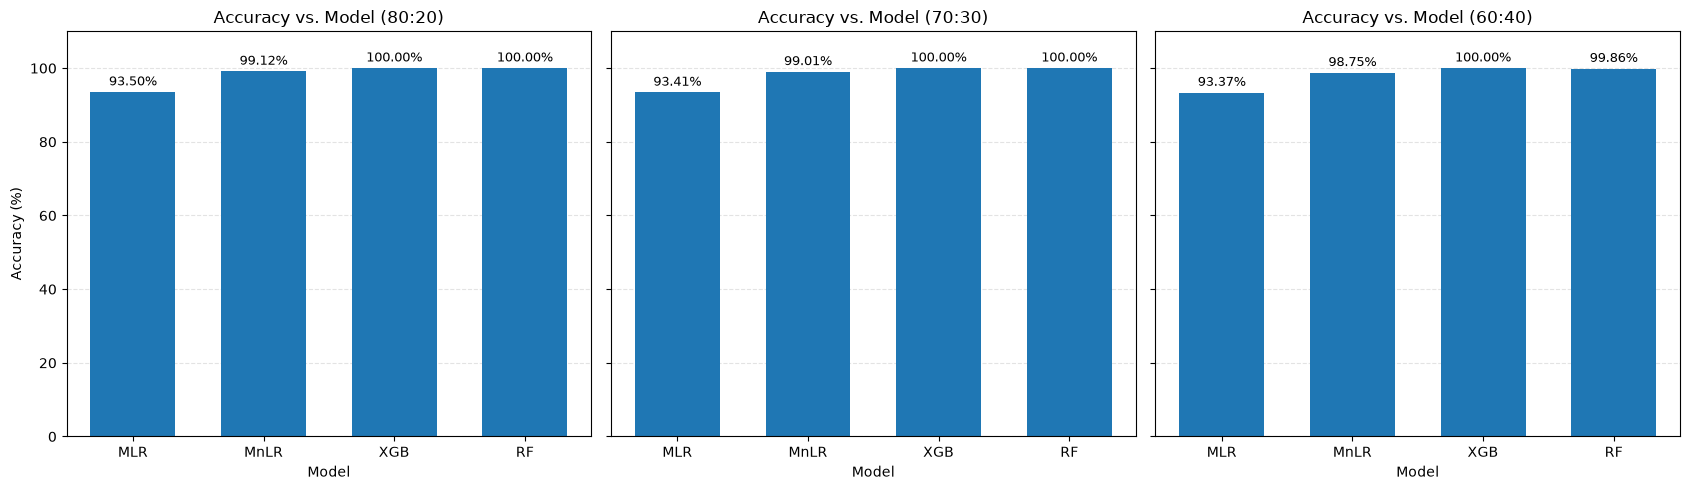

In [8]:

# ================================================================
# ROAD NOISE RISK PREDICTION
# Three Accuracy Graphs: 80:20, 70:30 and 60:40
# Dataset sheet: Road_noise_measurements
# ================================================================

# If needed, run once:
# %pip install pandas openpyxl scikit-learn matplotlib xgboost

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from tkinter import Tk, filedialog

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from xgboost import XGBClassifier

# ================================================================
# 1. SELECT AND LOAD THE EXCEL FILE
# ================================================================

root = Tk()
root.withdraw()
root.attributes("-topmost", True)

FILE_PATH = filedialog.askopenfilename(
    title="Select Road Noise Excel Dataset",
    filetypes=[("Excel files", "*.xlsx *.xls")]
)

root.destroy()

if not FILE_PATH:
    raise FileNotFoundError("No Excel file was selected.")

SHEET_NAME = "Road_noise_measurements"

# Read the first row as headers.
df = pd.read_excel(
    FILE_PATH,
    sheet_name=SHEET_NAME,
    header=0
)

df.columns = df.columns.astype(str).str.strip()

print("Dataset loaded successfully.")
print("Selected sheet:", SHEET_NAME)
print("Original dataset shape:", df.shape)
print("Available columns:", df.columns.tolist())

# ================================================================
# 2. VALIDATE COLUMNS
# ================================================================

features = [
    "TOWN",
    "LATITUDE",
    "LONGITUDE",
    "Duration_hours",
    "AVG_NOISE_LVL"
]

required_columns = features + ["Risk_Level"]

missing_columns = [
    col for col in required_columns if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing columns: {missing_columns}\n"
        f"Available columns: {df.columns.tolist()}"
    )

# ================================================================
# 3. CREATE RISK SCORE
# Low = 1, Moderate = 2, High = 3
# ================================================================

risk_mapping = {
    "Low": 1,
    "Moderate": 2,
    "High": 3
}

df["Risk_Level"] = (
    df["Risk_Level"].astype(str).str.strip().str.title()
)

df["Risk_Score"] = df["Risk_Level"].map(risk_mapping)

numeric_features = [
    "LATITUDE",
    "LONGITUDE",
    "Duration_hours",
    "AVG_NOISE_LVL"
]

for col in numeric_features:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df["TOWN"] = df["TOWN"].replace(
    r"^\s*$", np.nan, regex=True
)

# Remove rows without a valid target or town
df = df.dropna(subset=["Risk_Score", "TOWN"]).copy()
df["Risk_Score"] = df["Risk_Score"].astype(int)

X = df[features].copy()
y = df["Risk_Score"].copy()

print("\nRecords available after cleaning:", len(df))
print("\nRisk score distribution:")
print(y.value_counts().sort_index())

if set(y.unique()) != {1, 2, 3}:
    raise ValueError(
        "All three risk scores (1, 2, 3) must be present."
    )

# ================================================================
# 4. PREPROCESSING
# Fit preprocessing separately within each training split.
# ================================================================

def make_preprocessor(scale_numeric=False):

    numeric_steps = [
        ("imputer", SimpleImputer(strategy="median"))
    ]

    if scale_numeric:
        numeric_steps.append(
            ("scaler", StandardScaler())
        )

    numeric_transformer = Pipeline(numeric_steps)

    categorical_transformer = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ])

    return ColumnTransformer([
        ("town", categorical_transformer, ["TOWN"]),
        ("numeric", numeric_transformer, numeric_features)
    ])

# ================================================================
# 5. DEFINE MODELS
# ================================================================

def create_models():

    return {
        "MLR": Pipeline([
            ("preprocessor", make_preprocessor(True)),
            ("model", LinearRegression())
        ]),

        "MnLR": Pipeline([
            ("preprocessor", make_preprocessor(True)),
            ("model", LogisticRegression(
                solver="lbfgs",
                max_iter=2000,
                random_state=42
            ))
        ]),

        "XGB": Pipeline([
            ("preprocessor", make_preprocessor(False)),
            ("model", XGBClassifier(
                objective="multi:softprob",
                num_class=3,
                n_estimators=150,
                max_depth=5,
                learning_rate=0.08,
                subsample=0.9,
                colsample_bytree=0.9,
                eval_metric="mlogloss",
                random_state=42,
                n_jobs=-1
            ))
        ]),

        "RF": Pipeline([
            ("preprocessor", make_preprocessor(False)),
            ("model", RandomForestClassifier(
                n_estimators=200,
                class_weight="balanced",
                random_state=42,
                n_jobs=-1
            ))
        ])
    }

# ================================================================
# 6. TRAIN AND EVALUATE ALL THREE SPLITS
# ================================================================

splits = {
    "80:20": 0.20,
    "70:30": 0.30,
    "60:40": 0.40
}

results = {}

for split_name, test_size in splits.items():

    print(f"\n{'=' * 55}")
    print(f"TRAIN-TEST SPLIT: {split_name}")
    print(f"{'=' * 55}")

    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=test_size,
        random_state=42,
        stratify=y
    )

    print("Training records:", len(X_train))
    print("Testing records:", len(X_test))

    models = create_models()
    split_results = {}

    for model_name, model in models.items():

        if model_name == "XGB":
            # XGBoost expects labels 0, 1, 2.
            model.fit(X_train, y_train - 1)

            # Restore original labels 1, 2, 3.
            predictions = (
                model.predict(X_test).astype(int) + 1
            )

        else:
            model.fit(X_train, y_train)
            predictions = model.predict(X_test)

            if model_name == "MLR":
                # Convert regression scores into risk classes.
                predictions = np.clip(
                    np.rint(predictions), 1, 3
                ).astype(int)

        accuracy = accuracy_score(
            y_test, predictions
        ) * 100

        split_results[model_name] = accuracy

        print(f"{model_name} Accuracy: {accuracy:.2f}%")

    results[split_name] = split_results

# ================================================================
# 7. DISPLAY ACCURACY TABLE
# ================================================================

results_df = pd.DataFrame(results).T
results_df.index.name = "Train-Test Split"

print("\nFINAL ACCURACY COMPARISON (%)")
display(results_df.round(2))

# ================================================================
# 8. GENERATE EXACTLY THREE GRAPHS
# ================================================================

model_order = ["MLR", "MnLR", "XGB", "RF"]

fig, axes = plt.subplots(
    1, 3,
    figsize=(17, 5),
    sharey=True
)

for ax, split_name in zip(axes, splits.keys()):

    values = [
        results[split_name][name]
        for name in model_order
    ]

    bars = ax.bar(
        model_order,
        values,
        width=0.65
    )

    ax.set_title(
        f"Accuracy vs. Model ({split_name})",
        fontsize=12
    )

    ax.set_xlabel("Model")
    ax.set_ylim(0, 110)
    ax.grid(
        axis="y",
        linestyle="--",
        alpha=0.35
    )
    ax.set_axisbelow(True)

    for bar, value in zip(bars, values):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 1,
            f"{value:.2f}%",
            ha="center",
            va="bottom",
            fontsize=9
        )

axes[0].set_ylabel("Accuracy (%)")

plt.tight_layout()
plt.show()

# ================================================================
# END
# ================================================================


F1-Score Comparison (%)


,MLR,MnLR,XGB,RF
Train-Test Split,,,,
80:20,93.50,99.12,100.0,100.00
70:30,93.41,99.01,100.0,100.00
60:40,93.37,98.75,100.0,99.86


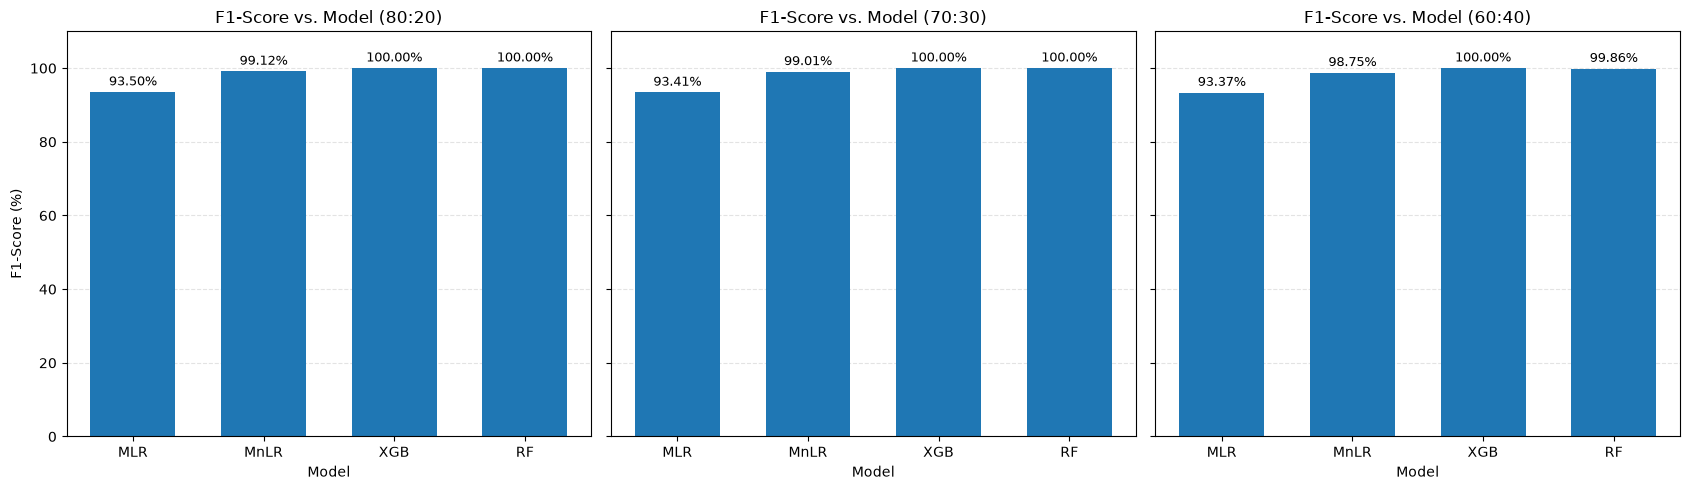

In [9]:

from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Store F1 scores for each split
f1_results = {}

model_order = ["MLR", "MnLR", "XGB", "RF"]

for split_name, test_size in splits.items():

    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=test_size,
        random_state=42,
        stratify=y
    )

    models = create_models()
    split_f1 = {}

    for model_name, model in models.items():

        if model_name == "XGB":
            # XGBoost uses class labels 0, 1, 2
            model.fit(X_train, y_train - 1)
            predictions = model.predict(X_test).astype(int) + 1

        else:
            model.fit(X_train, y_train)
            predictions = model.predict(X_test)

            if model_name == "MLR":
                predictions = np.clip(
                    np.rint(predictions), 1, 3
                ).astype(int)

        # Weighted F1-score for the three risk classes
        score = f1_score(
            y_test,
            predictions,
            labels=[1, 2, 3],
            average="weighted",
            zero_division=0
        ) * 100

        split_f1[model_name] = score

    f1_results[split_name] = split_f1

# Display F1-score results
f1_df = pd.DataFrame(f1_results).T
f1_df.index.name = "Train-Test Split"

print("F1-Score Comparison (%)")
display(f1_df.round(2))

# Generate three F1-score graphs
fig, axes = plt.subplots(
    1, 3,
    figsize=(17, 5),
    sharey=True
)

for ax, split_name in zip(axes, splits.keys()):

    values = [
        f1_results[split_name][name]
        for name in model_order
    ]

    bars = ax.bar(
        model_order,
        values,
        width=0.65
    )

    ax.set_title(
        f"F1-Score vs. Model ({split_name})",
        fontsize=12
    )
    ax.set_xlabel("Model")
    ax.set_ylim(0, 110)
    ax.grid(axis="y", linestyle="--", alpha=0.35)
    ax.set_axisbelow(True)

    for bar, value in zip(bars, values):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 1,
            f"{value:.2f}%",
            ha="center",
            va="bottom",
            fontsize=9
        )

axes[0].set_ylabel("F1-Score (%)")

plt.tight_layout()
plt.show()


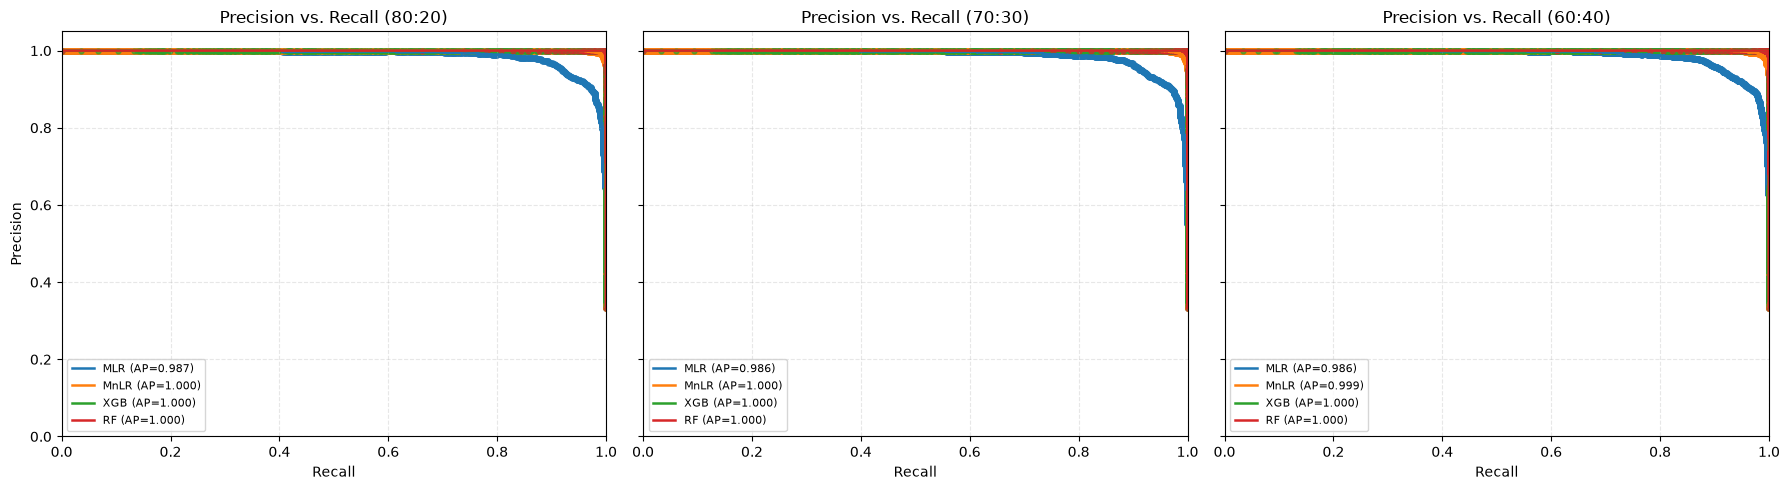

In [15]:

# ============================================================
# PRECISION vs RECALL: MARK POINTS, THEN CONNECT THEM
# ============================================================

import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

model_order = ["MLR", "MnLR", "XGB", "RF"]

for ax, split_name in zip(axes, splits.keys()):

    for model_name in model_order:

        precision, recall, ap = pr_results[split_name][model_name]

        precision = np.asarray(precision)
        recall = np.asarray(recall)

        # Sort measured points by increasing recall
        order = np.argsort(recall)
        recall = recall[order]
        precision = precision[order]

        # Mark the measured precision-recall points
        ax.scatter(
            recall,
            precision,
            s=12,
            alpha=0.65
        )

        # Connect measured points, starting from the leftmost point
        # (the actual PR curve's endpoint may not be (0, 0)).
        ax.plot(
            recall,
            precision,
            linewidth=1.8,
            label=f"{model_name} (AP={ap:.3f})"
        )

    ax.set_title(f"Precision vs. Recall ({split_name})")
    ax.set_xlabel("Recall")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.05)
    ax.grid(True, linestyle="--", alpha=0.3)
    ax.legend(fontsize=8)

axes[0].set_ylabel("Precision")
plt.tight_layout()
plt.show()


Calculating ROC curves for 80:20...
Calculating ROC curves for 70:30...
Calculating ROC curves for 60:40...


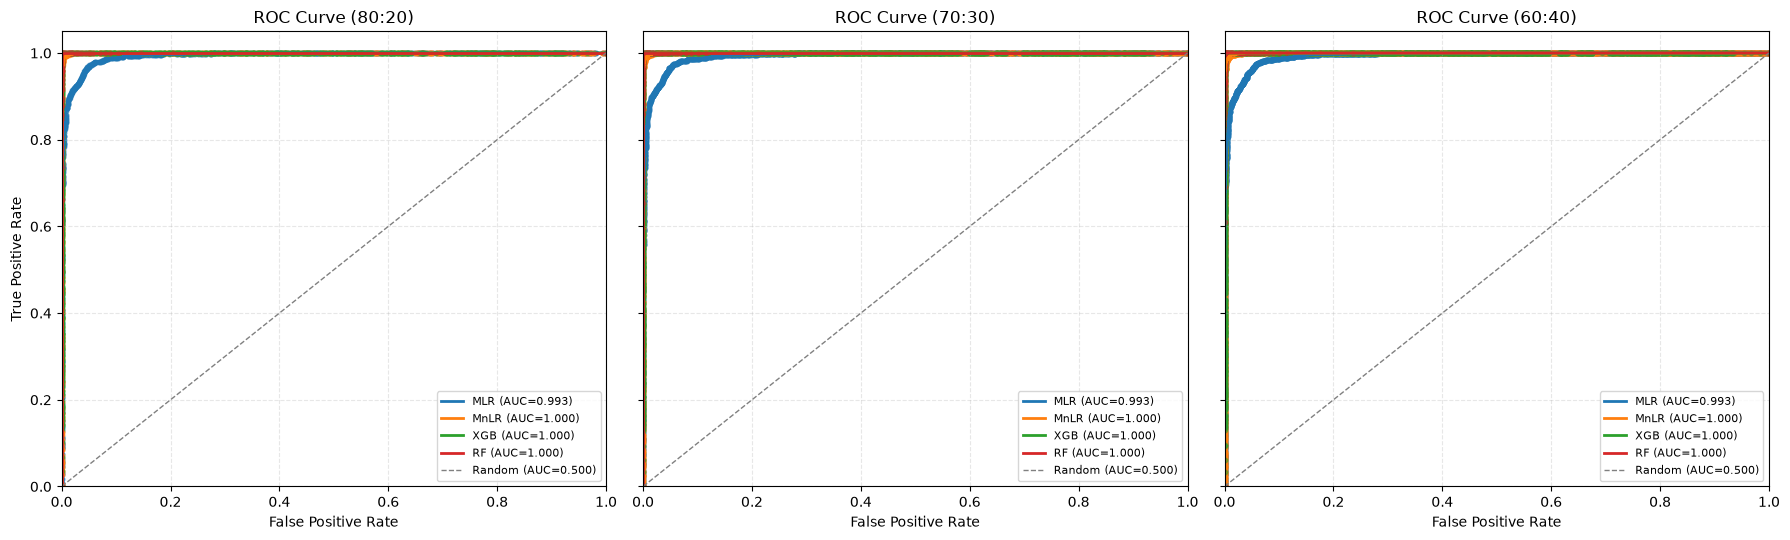

Micro-average ROC-AUC scores:


,MLR,MnLR,XGB,RF
Train-Test Split,,,,
80:20,0.9932,0.9998,1.0,1.0
70:30,0.9927,0.9998,1.0,1.0
60:40,0.9927,0.9997,1.0,1.0


In [16]:

# ============================================================
# ROC CURVES FOR FOUR MODELS
# 80:20, 70:30 and 60:40 train-test splits
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc, roc_auc_score

classes = [1, 2, 3]
model_order = ["MLR", "MnLR", "XGB", "RF"]

roc_results = {}

for split_name, test_size in splits.items():

    print(f"Calculating ROC curves for {split_name}...")

    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=test_size,
        random_state=42,
        stratify=y
    )

    y_test_binary = label_binarize(y_test, classes=classes)
    split_results = {}

    for name, model in create_models().items():

        if name == "XGB":
            model.fit(X_train, y_train - 1)
            raw_scores = model.predict_proba(X_test)
            model_classes = [1, 2, 3]

        elif name == "MLR":
            model.fit(X_train, y_train)
            predictions = model.predict(X_test)

            # Convert continuous predictions to class-closeness scores
            raw_scores = np.column_stack([
                -np.abs(predictions - cls) for cls in classes
            ])
            model_classes = classes

        else:
            model.fit(X_train, y_train)
            raw_scores = model.predict_proba(X_test)
            model_classes = model.named_steps["model"].classes_

        # Align scores with classes 1, 2, 3
        scores = np.zeros((len(X_test), len(classes)))

        for j, cls in enumerate(model_classes):
            scores[:, int(cls) - 1] = raw_scores[:, j]

        # Micro-average ROC curve
        fpr, tpr, _ = roc_curve(
            y_test_binary.ravel(),
            scores.ravel()
        )

        roc_auc = auc(fpr, tpr)

        split_results[name] = {
            "fpr": fpr,
            "tpr": tpr,
            "auc": roc_auc
        }

    roc_results[split_name] = split_results

# ============================================================
# PLOT THREE ROC GRAPHS
# ============================================================

fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 5.5),
    sharey=True
)

for ax, split_name in zip(axes, splits.keys()):

    for name in model_order:

        result = roc_results[split_name][name]
        fpr = result["fpr"]
        tpr = result["tpr"]
        model_auc = result["auc"]

        # Mark ROC points and connect them
        ax.scatter(fpr, tpr, s=10, alpha=0.5)
        ax.plot(
            fpr,
            tpr,
            linewidth=2,
            label=f"{name} (AUC={model_auc:.3f})"
        )

    # Random-classifier reference
    ax.plot(
        [0, 1], [0, 1],
        linestyle="--",
        linewidth=1,
        color="gray",
        label="Random (AUC=0.500)"
    )

    ax.set_title(f"ROC Curve ({split_name})")
    ax.set_xlabel("False Positive Rate")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.05)
    ax.grid(True, linestyle="--", alpha=0.3)
    ax.legend(fontsize=8, loc="lower right")

axes[0].set_ylabel("True Positive Rate")

plt.tight_layout()
plt.show()

# ============================================================
# DISPLAY AUC SUMMARY
# ============================================================

auc_table = pd.DataFrame({
    split_name: {
        name: roc_results[split_name][name]["auc"]
        for name in model_order
    }
    for split_name in splits
}).T

auc_table.index.name = "Train-Test Split"

print("Micro-average ROC-AUC scores:")
display(auc_table.round(4))


In [ ]:

# ============================================================
# ROBUSTNESS ANALYSIS: MACRO-F1 ACROSS TRAIN-TEST SPLITS
# Models: MLR, MnLR, XGB, RF
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score

model_order = ["MLR", "MnLR", "XGB", "RF"]
robustness_results = {}

for split_name, test_size in splits.items():

    X_train, X_test, y_train, y_test = train_test_split(
        X, y,
        test_size=test_size,
        random_state=42,
        stratify=y
    )

    split_scores = {}

    for name, model in create_models().items():

        if name == "XGB":
            model.fit(X_train, y_train - 1)
            predictions = model.predict(X_test).astype(int) + 1

        else:
            model.fit(X_train, y_train)
            predictions = model.predict(X_test)

            if name == "MLR":
                predictions = np.clip(
                    np.rint(predictions), 1, 3
                ).astype(int)

        score = f1_score(
            y_test,
            predictions,
            labels=[1, 2, 3],
            average="macro",
            zero_division=0
        ) * 100

        split_scores[name] = score

    robustness_results[split_name] = split_scores

# Results table
robustness_df = pd.DataFrame(
    robustness_results
).T[model_order]

robustness_df.index.name = "Train-Test Split"

print("Robustness Results — Macro-F1 (%)")
display(robustness_df.round(2))

# ============================================================
# PLOT ROBUSTNESS GRAPH
# ============================================================

fig, ax = plt.subplots(figsize=(9, 5.5))

split_labels = list(splits.keys())
x_positions = np.arange(len(split_labels))

for model_name in model_order:

    scores = [
        robustness_results[split_name][model_name]
        for split_name in split_labels
    ]

    ax.plot(
        x_positions,
        scores,
        marker="o",
        markersize=7,
        linewidth=2,
        label=model_name
    )

    # Label each measured point
    for x_pos, score in zip(x_positions, scores):
        ax.annotate(
            f"{score:.1f}%",
            (x_pos, score),
            textcoords="offset points",
            xytext=(0, 8),
            ha="center",
            fontsize=8
        )

ax.set_xticks(x_positions)
ax.set_xticklabels(split_labels)
ax.set_xlabel("Train-Test Split")
ax.set_ylabel("Macro-F1 Score (%)")
ax.set_title("Model Robustness Across Train-Test Splits")

ax.set_ylim(0, 105)
ax.grid(True, linestyle="--", alpha=0.35)
ax.legend(title="Model")

plt.tight_layout()
plt.show()
